<a href="https://colab.research.google.com/github/prosettibu/spatial-gnn-visium/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q squidpy torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 6.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.5/280.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.6/51.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10

In [2]:
import torch
import squidpy as sq
import scanpy as sc

print(torch.__version__, torch.cuda.is_available())

adata = sq.datasets.visium_hne_adata()
print(adata)
print(adata.obs["cluster"].value_counts())
print(adata.obsm["spatial"][:5])

2.11.0+cpu False
INFO     Downloading visium_hne_adata.h5ad from https://exampledata.scverse.org/squidpy/visium_hne_adata.h5ad      


  0%|                                               | 0.00/329M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)
cluster
Cortex_1                         284
Thalamus_1                       261
Cortex_2      

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

# normalize only if X is raw counts
if adata.X.max() > 50:
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

# features: top 2000 highly variable genes
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat")
X = adata[:, adata.var.highly_variable].X
X = X.toarray() if hasattr(X, "toarray") else X

# labels as integers 0–14
labels = adata.obs["cluster"].cat.codes.values
class_names = list(adata.obs["cluster"].cat.categories)

# split by spot index, stratified so rare classes appear in both sets
idx = np.arange(adata.n_obs)
train_idx, val_idx = train_test_split(idx, test_size=0.2, stratify=labels, random_state=0)

X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(labels, dtype=torch.long)
print(X_t.shape, y_t.shape, len(train_idx), len(val_idx))

torch.Size([2688, 2000]) torch.Size([2688]) 2150 538


In [4]:
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
X_t, y_t = X_t.to(device), y_t.to(device)
train_idx_t = torch.tensor(train_idx, device=device)
val_idx_t = torch.tensor(val_idx, device=device)

class MLP(nn.Module):
    def __init__(self, in_dim, hidden, n_classes, dropout=0.5):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, n_classes)
        self.dropout = dropout

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.fc2(x)  # raw scores (logits), one per class

torch.manual_seed(0)
model = MLP(X_t.shape[1], 128, len(class_names)).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=5e-4)

def evaluate(idx):
    model.eval()
    with torch.no_grad():
        pred = model(X_t)[idx].argmax(1)
    return (pred == y_t[idx]).float().mean().item()

for epoch in range(200):
    model.train()
    opt.zero_grad()                                             # 1. clear old gradients
    out = model(X_t)                                            # 2. forward pass on all spots
    loss = F.cross_entropy(out[train_idx_t], y_t[train_idx_t])  # 3. loss on train spots only
    loss.backward()                                             # 4. compute gradients
    opt.step()                                                  # 5. update weights
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}  loss {loss.item():.3f}  train {evaluate(train_idx_t):.3f}  val {evaluate(val_idx_t):.3f}")

mlp_val_acc = evaluate(val_idx_t)
print("MLP val acc:", mlp_val_acc)

epoch   0  loss 2.734  train 0.271  val 0.264
epoch  20  loss 0.646  train 0.916  val 0.864
epoch  40  loss 0.264  train 0.978  val 0.920
epoch  60  loss 0.152  train 0.996  val 0.918
epoch  80  loss 0.082  train 1.000  val 0.924
epoch 100  loss 0.067  train 1.000  val 0.926
epoch 120  loss 0.048  train 1.000  val 0.924
epoch 140  loss 0.038  train 1.000  val 0.924
epoch 160  loss 0.031  train 1.000  val 0.928
epoch 180  loss 0.024  train 1.000  val 0.926
MLP val acc: 0.9275093078613281


In [5]:
# connect each Visium spot to its 6 hexagonal neighbors
sq.gr.spatial_neighbors(adata, coord_type="grid", n_neighs=6)
A = adata.obsp["spatial_connectivities"].tocoo()

edge_index = torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long).to(device)
print(edge_index.shape)
print("avg neighbors:", edge_index.shape[1] / adata.n_obs)

# fraction of edges that connect two spots with the same label
same = (y_t[edge_index[0]] == y_t[edge_index[1]]).float().mean().item()
print("edge homophily:", same)

INFO     Creating graph using `None` transform and `1` libraries.                                                  
torch.Size([2, 15580])
avg neighbors: 5.7961309523809526
edge homophily: 0.7636713981628418


/tmp/ipykernel_2873/3212599966.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="grid", n_neighs=6)


In [6]:
from torch_geometric.nn import GCNConv

class GCN(nn.Module):
    def __init__(self, in_dim, hidden, n_classes, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, n_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))   # aggregate neighbors, then transform
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

torch.manual_seed(0)
gnn = GCN(X_t.shape[1], 128, len(class_names)).to(device)
opt = torch.optim.Adam(gnn.parameters(), lr=1e-3, weight_decay=5e-4)

def evaluate_gnn(idx):
    gnn.eval()
    with torch.no_grad():
        pred = gnn(X_t, edge_index)[idx].argmax(1)
    return (pred == y_t[idx]).float().mean().item()

for epoch in range(200):
    gnn.train()
    opt.zero_grad()
    out = gnn(X_t, edge_index)
    loss = F.cross_entropy(out[train_idx_t], y_t[train_idx_t])
    loss.backward()
    opt.step()
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}  loss {loss.item():.3f}  train {evaluate_gnn(train_idx_t):.3f}  val {evaluate_gnn(val_idx_t):.3f}")

gnn_val_acc = evaluate_gnn(val_idx_t)
print(f"MLP val acc: {mlp_val_acc:.3f}   GNN val acc: {gnn_val_acc:.3f}")

epoch   0  loss 3.351  train 0.164  val 0.165
epoch  20  loss 0.727  train 0.826  val 0.816
epoch  40  loss 0.436  train 0.873  val 0.848
epoch  60  loss 0.340  train 0.908  val 0.883
epoch  80  loss 0.284  train 0.922  val 0.887
epoch 100  loss 0.252  train 0.930  val 0.892
epoch 120  loss 0.240  train 0.936  val 0.903
epoch 140  loss 0.213  train 0.943  val 0.900
epoch 160  loss 0.200  train 0.945  val 0.903
epoch 180  loss 0.192  train 0.953  val 0.898
MLP val acc: 0.928   GNN val acc: 0.894


In [8]:
from torch_geometric.nn import SAGEConv

class GCN(nn.Module):
    def __init__(self, in_dim, hidden, n_classes, dropout=0.5):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden)
        self.conv2 = SAGEConv(hidden, n_classes)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))   # aggregate neighbors, then transform
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

torch.manual_seed(0)
gnn = GCN(X_t.shape[1], 128, len(class_names)).to(device)
opt = torch.optim.Adam(gnn.parameters(), lr=1e-3, weight_decay=5e-4)

def evaluate_gnn(idx):
    gnn.eval()
    with torch.no_grad():
        pred = gnn(X_t, edge_index)[idx].argmax(1)
    return (pred == y_t[idx]).float().mean().item()

for epoch in range(200):
    gnn.train()
    opt.zero_grad()
    out = gnn(X_t, edge_index)
    loss = F.cross_entropy(out[train_idx_t], y_t[train_idx_t])
    loss.backward()
    opt.step()
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}  loss {loss.item():.3f}  train {evaluate_gnn(train_idx_t):.3f}  val {evaluate_gnn(val_idx_t):.3f}")

gnn_val_acc = evaluate_gnn(val_idx_t)
print(f"MLP val acc: {mlp_val_acc:.3f}   GNN val acc: {gnn_val_acc:.3f}")

epoch   0  loss 2.942  train 0.200  val 0.197
epoch  20  loss 0.601  train 0.875  val 0.838
epoch  40  loss 0.293  train 0.947  val 0.903
epoch  60  loss 0.183  train 0.966  val 0.924
epoch  80  loss 0.125  train 0.988  val 0.937
epoch 100  loss 0.091  train 0.996  val 0.933
epoch 120  loss 0.066  train 0.999  val 0.933
epoch 140  loss 0.058  train 1.000  val 0.935
epoch 160  loss 0.049  train 1.000  val 0.935
epoch 180  loss 0.039  train 1.000  val 0.929
MLP val acc: 0.928   GNN val acc: 0.935


In [9]:
def train_eval(model_cls, use_graph, seed, epochs=150):
    torch.manual_seed(seed)
    tr, va = train_test_split(idx, test_size=0.2, stratify=labels, random_state=seed)
    tr = torch.tensor(tr, device=device)
    va = torch.tensor(va, device=device)
    m = model_cls(X_t.shape[1], 128, len(class_names)).to(device)
    o = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=5e-4)
    fwd = (lambda: m(X_t, edge_index)) if use_graph else (lambda: m(X_t))
    for _ in range(epochs):
        m.train()
        o.zero_grad()
        loss = F.cross_entropy(fwd()[tr], y_t[tr])
        loss.backward()
        o.step()
    m.eval()
    with torch.no_grad():
        return (fwd()[va].argmax(1) == y_t[va]).float().mean().item()

mlp_accs, sage_accs = [], []
for seed in range(10):
    mlp_accs.append(train_eval(MLP, False, seed))
    sage_accs.append(train_eval(GCN, True, seed))   # GCN class now uses SAGEConv
    print(f"seed {seed}  MLP {mlp_accs[-1]:.3f}  SAGE {sage_accs[-1]:.3f}")

mlp_accs, sage_accs = np.array(mlp_accs), np.array(sage_accs)
diff = sage_accs - mlp_accs
print(f"\nMLP  {mlp_accs.mean():.3f} ± {mlp_accs.std():.3f}")
print(f"SAGE {sage_accs.mean():.3f} ± {sage_accs.std():.3f}")
print(f"SAGE − MLP: {diff.mean():+.3f}, SAGE wins {(diff > 0).sum()}/10")

seed 0  MLP 0.924  SAGE 0.937
seed 1  MLP 0.952  SAGE 0.929
seed 2  MLP 0.941  SAGE 0.939
seed 3  MLP 0.961  SAGE 0.955
seed 4  MLP 0.926  SAGE 0.926
seed 5  MLP 0.937  SAGE 0.941
seed 6  MLP 0.942  SAGE 0.933
seed 7  MLP 0.933  SAGE 0.933
seed 8  MLP 0.965  SAGE 0.965
seed 9  MLP 0.950  SAGE 0.931

MLP  0.943 ± 0.013
SAGE 0.939 ± 0.012
SAGE − MLP: -0.004, SAGE wins 2/10


In [10]:
# rank all genes by variability (most variable first)
order = np.argsort(-adata.var["dispersions_norm"].fillna(-np.inf).values)
X_all = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

def train_eval(X, model_cls, use_graph, seed, epochs=150):
    torch.manual_seed(seed)
    tr, va = train_test_split(idx, test_size=0.2, stratify=labels, random_state=seed)
    tr = torch.tensor(tr, device=device)
    va = torch.tensor(va, device=device)
    m = model_cls(X.shape[1], 128, len(class_names)).to(device)
    o = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=5e-4)
    fwd = (lambda: m(X, edge_index)) if use_graph else (lambda: m(X))
    for _ in range(epochs):
        m.train()
        o.zero_grad()
        loss = F.cross_entropy(fwd()[tr], y_t[tr])
        loss.backward()
        o.step()
    m.eval()
    with torch.no_grad():
        return (fwd()[va].argmax(1) == y_t[va]).float().mean().item()

results = []
for k in [2000, 500, 100, 50, 20, 10]:
    Xk = torch.tensor(X_all[:, order[:k]], dtype=torch.float32, device=device)
    m_acc = np.array([train_eval(Xk, MLP, False, s) for s in range(10)])
    s_acc = np.array([train_eval(Xk, GCN, True, s) for s in range(10)])
    d = s_acc - m_acc
    results.append((k, m_acc.mean(), m_acc.std(), s_acc.mean(), s_acc.std()))
    print(f"{k:5d} genes  MLP {m_acc.mean():.3f}  SAGE {s_acc.mean():.3f}  "
          f"gap {d.mean():+.3f}  SAGE wins {(d > 0).sum()}/10")

 2000 genes  MLP 0.942  SAGE 0.938  gap -0.003  SAGE wins 3/10
  500 genes  MLP 0.917  SAGE 0.926  gap +0.009  SAGE wins 8/10
  100 genes  MLP 0.774  SAGE 0.875  gap +0.101  SAGE wins 10/10
   50 genes  MLP 0.525  SAGE 0.764  gap +0.239  SAGE wins 10/10
   20 genes  MLP 0.346  SAGE 0.546  gap +0.200  SAGE wins 10/10
   10 genes  MLP 0.246  SAGE 0.354  gap +0.108  SAGE wins 10/10


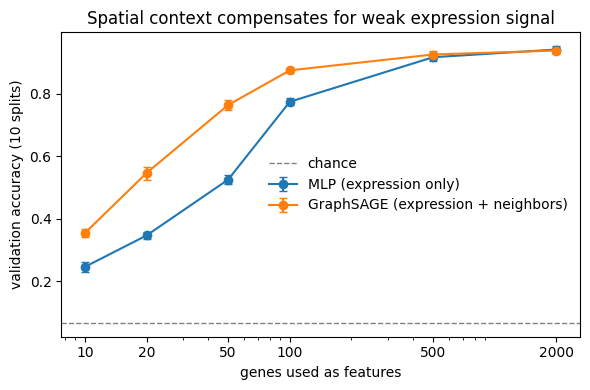

In [11]:
import matplotlib.pyplot as plt

r = np.array(results)
k, m_mean, m_std, s_mean, s_std = r.T

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(k, m_mean, yerr=m_std, marker="o", capsize=3, label="MLP (expression only)")
ax.errorbar(k, s_mean, yerr=s_std, marker="o", capsize=3, label="GraphSAGE (expression + neighbors)")
ax.axhline(1 / len(class_names), ls="--", c="gray", lw=1, label="chance")
ax.set_xscale("log")
ax.set_xticks(k)
ax.set_xticklabels([int(x) for x in k])
ax.set_xlabel("genes used as features")
ax.set_ylabel("validation accuracy (10 splits)")
ax.set_title("Spatial context compensates for weak expression signal")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("spatial_vs_expression.png", dpi=200)
plt.show()